--- [STEP 1 & 2] Loading Data and Performing EDA ---
Dataset Shape after cleaning: (110, 15)
Missing Values:
user_id                 0
session_id              0
stage                   0
age                     0
screen_width            0
screen_height           0
total_taps              0
successful_taps         0
miss_taps               0
tap_accuracy            0
avg_reaction_time_ms    0
button_label            0
miss_rate               0
reaction_norm           0
overall_score           0
dtype: int64
Target Distribution:
button_label
extra_large_button_ui    0.254545
small_button_ui          0.254545
default_button_ui        0.245455
large_button_ui          0.245455
Name: proportion, dtype: float64


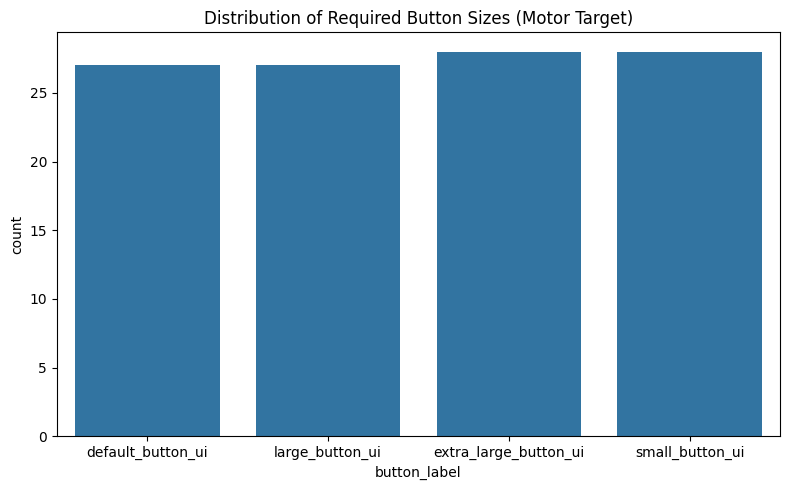


--- [STEP 3] Preprocessing ---
Preprocessing Complete. Features extracted: ['age', 'screen_width', 'screen_height', 'total_taps', 'successful_taps', 'miss_taps', 'tap_accuracy', 'avg_reaction_time_ms', 'miss_rate', 'reaction_norm']

--- [STEP 4] Train/Test Split ---
Training set: (88, 10), Test set: (22, 10)

--- [STEP 5, 7, 8] Training and Evaluation ---
Training Decision Tree...
Training Random Forest...
Training XGBoost Base...
Training MLP Classifier...

--- [STEP 6] Hyperparameter Tuning for XGBoost ---
Best Parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'subsample': 1.0}

--- [STEP 9] Model Comparison ---
            Model  CV_Accuracy    CV_Std  Test_Accuracy  Balanced_Accuracy  \
1   Random Forest     0.841176  0.040901       0.863636           0.866667   
2    XGBoost Base     0.805882  0.107726       0.818182           0.816667   
4   XGBoost Tuned     0.805882  0.107726       0.818182           0.816667   
3  MLP Classifier     0.830065  0.033263   

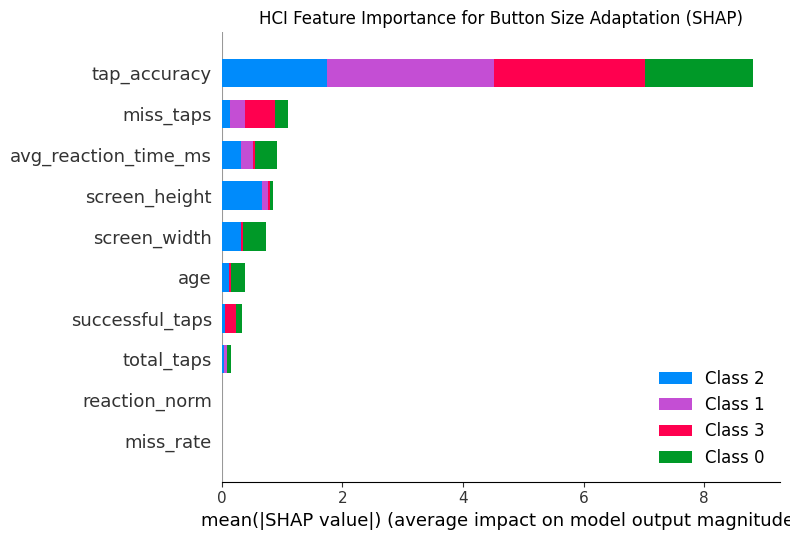


--- [STEP 12 & 13] Saving Models and Pipeline ---
Artifacts saved successfully.

--- [PREDICTION] Recommending Button Size for App Interface ---
Input Metrics: {'age': 23, 'screen_width': 1080, 'screen_height': 2400, 'total_taps': 10, 'successful_taps': 6, 'miss_taps': 4, 'tap_accuracy': 0.5, 'avg_reaction_time_ms': 380, 'miss_rate': 0.25, 'reaction_norm': 0.8, 'overall_score': 0.5}
👉 Recommended Button Size for App: default_button_ui


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
from datetime import datetime

# ML & Scikit-Learn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, matthews_corrcoef, cohen_kappa_score,
                             confusion_matrix, classification_report, log_loss)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

# Explainability
import shap

warnings.filterwarnings('ignore')

class AUI_ButtonSize_Pipeline:
    def __init__(self, csv_path=None):
        self.csv_path = csv_path  
        self.df = None
        self.target_col = 'button_label'
        self.models = {}
        self.results = {}
        self.best_model = None
        
        # Artifacts
        self.label_encoder = LabelEncoder()
        self.scaler = StandardScaler()
        self.features = []

    # ==========================================
    # STEP 1 & 2: Load Data and EDA
    # ==========================================
    def load_and_eda(self):
        """Loads updated dataset and performs comprehensive Exploratory Data Analysis."""
        print("--- [STEP 1 & 2] Loading Data and Performing EDA ---")
        if self.csv_path:
            raw_df = pd.read_csv(self.csv_path)  
        else:
            print("[INFO] No CSV provided.")
            return

        # Domain/Dataset Cleaning for AUI framework
        df_clean = raw_df.copy()
        
        # Remove inactive sessions if total_taps exists and is 0
        if 'total_taps' in df_clean.columns:
            df_clean = df_clean[df_clean['total_taps'] > 0]
            
        # Remove invalid ages if age exists
        if 'age' in df_clean.columns:
            df_clean = df_clean[df_clean['age'] <= 100]

        self.df = df_clean

        # EDA execution
        print(f"Dataset Shape after cleaning: {self.df.shape}")
        print(f"Missing Values:\n{self.df.isnull().sum()}")
        print(f"Target Distribution:\n{self.df[self.target_col].value_counts(normalize=True)}")
        
        # Plotting distributions (HCI behavior focus)
        plt.figure(figsize=(8, 5))
        sns.countplot(x=self.target_col, data=self.df)
        plt.title("Distribution of Required Button Sizes (Motor Target)")
        plt.tight_layout()
        plt.show()

    # ==========================================
    # STEP 3: Preprocessing
    # ==========================================
    def preprocess_data(self):
        """Handles missing values, encodes targets, and scales HCI features."""
        print("\n--- [STEP 3] Preprocessing ---")
        if self.df is None: return None, None
        
        df_clean = self.df.copy()
        numeric_cols = df_clean.select_dtypes(include=[np.number]).columns
        df_clean[numeric_cols] = df_clean[numeric_cols].fillna(df_clean[numeric_cols].median())

        # Target Encoding
        y = self.label_encoder.fit_transform(df_clean[self.target_col])

        # Feature Selection (Dropping target and non-feature columns)
        drop_cols = [
            self.target_col,
            "user_id",
            "session_id",
            "stage",
            "overall_score",
            "IFI"
        ]
        
        # Keep only columns that actually exist in the dataframe
        drop_cols = [c for c in drop_cols if c in df_clean.columns]
        X = df_clean.drop(columns=drop_cols)

        # Feature List
        self.features = X.columns.tolist()

        # Feature Scaling
        X_scaled = pd.DataFrame(
            self.scaler.fit_transform(X),
            columns=self.features
        )
        
        print("Preprocessing Complete. Features extracted:", self.features)
        return X_scaled, y

    # ==========================================
    # STEP 4: Train/Test Split
    # ==========================================
    def split_data(self, X, y):
        print("\n--- [STEP 4] Train/Test Split ---")
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.20, stratify=y, random_state=42
        )
        print(f"Training set: {X_train.shape}, Test set: {X_test.shape}")
        return X_train, X_test, y_train, y_test

    # ==========================================
    # STEP 5 & 7 & 8: Train, Cross-Validate, Evaluate
    # ==========================================
    def evaluate_model(self, model, X_train, y_train, X_test, y_test, model_name):
        skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        cv_scores = []
        
        X_tr_arr = X_train.values if isinstance(X_train, pd.DataFrame) else X_train
        y_tr_arr = y_train.values if isinstance(y_train, pd.Series) else y_train
        
        for train_idx, val_idx in skf.split(X_tr_arr, y_tr_arr):
            clone_model = type(model)(**model.get_params())
            clone_model.fit(X_tr_arr[train_idx], y_tr_arr[train_idx])
            cv_scores.append(clone_model.score(X_tr_arr[val_idx], y_tr_arr[val_idx]))
        
        import time
        start_time = time.time()
        model.fit(X_train, y_train)
        train_time = time.time() - start_time
        
        start_time = time.time()
        y_pred = model.predict(X_test)
        pred_time = time.time() - start_time

        acc = accuracy_score(y_test, y_pred)
        bal_acc = balanced_accuracy_score(y_test, y_pred)
        mcc = matthews_corrcoef(y_test, y_pred)
        kappa = cohen_kappa_score(y_test, y_pred)
        
        metrics = {
            "Model": model_name,
            "CV_Accuracy": np.mean(cv_scores),
            "CV_Std": np.std(cv_scores),
            "Test_Accuracy": acc,
            "Balanced_Accuracy": bal_acc,
            "F1_Weighted": f1_score(y_test, y_pred, average='weighted'),
            "Precision": precision_score(y_test, y_pred, average='weighted'),
            "Recall": recall_score(y_test, y_pred, average='weighted'),
            "MCC": mcc,
            "Cohen_Kappa": kappa,
            "Train_Time(s)": train_time,
            "Pred_Time(s)": pred_time
        }
        
        self.results[model_name] = metrics
        return model, y_pred

    def train_all_models(self, X_train, y_train, X_test, y_test):
        print("\n--- [STEP 5, 7, 8] Training and Evaluation ---")
        
        models_to_train = {
            "Decision Tree": DecisionTreeClassifier(random_state=42),
            "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
            "XGBoost Base": XGBClassifier(eval_metric='mlogloss', random_state=42),
            "MLP Classifier": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=42)
        }

        for name, clf in models_to_train.items():
            print(f"Training {name}...")
            trained_model, _ = self.evaluate_model(clf, X_train, y_train, X_test, y_test, name)
            self.models[name] = trained_model

    # ==========================================
    # STEP 6: XGBoost Hyperparameter Tuning
    # ==========================================
    def tune_xgboost(self, X_train, y_train):
        print("\n--- [STEP 6] Hyperparameter Tuning for XGBoost ---")
        xgb_clf = XGBClassifier(eval_metric='mlogloss', random_state=42)
        
        param_grid = {
            'max_depth': [3, 5, 7],
            'learning_rate': [0.01, 0.1, 0.2],
            'n_estimators': [100, 200],
            'subsample': [0.8, 1.0]
        }
        
        grid_search = GridSearchCV(estimator=xgb_clf, param_grid=param_grid, 
                                   cv=StratifiedKFold(n_splits=3), scoring='f1_weighted', n_jobs=-1)
        grid_search.fit(X_train, y_train)
        
        print(f"Best Parameters: {grid_search.best_params_}")
        best_xgb = grid_search.best_estimator_
        self.models['XGBoost Tuned'] = best_xgb
        self.best_model = best_xgb
        return best_xgb

    # ==========================================
    # STEP 9: Model Comparison
    # ==========================================
    def compare_models(self):
        print("\n--- [STEP 9] Model Comparison ---")
        df_results = pd.DataFrame(self.results.values())
        print(df_results.sort_values(by="F1_Weighted", ascending=False))
        df_results.to_csv("aui_model_comparison_results.csv", index=False)
        return df_results

    # ==========================================
    # STEP 10: Explainability (SHAP for AUI)
    # ==========================================
    def explain_model(self, X_train):
        print("\n--- [STEP 10] SHAP Explainability ---")
        explainer = shap.TreeExplainer(self.best_model)
        shap_values = explainer.shap_values(X_train)
        
        plt.figure(figsize=(10, 6))
        shap.summary_plot(shap_values, X_train, plot_type="bar", show=False)
        plt.title("HCI Feature Importance for Button Size Adaptation (SHAP)")
        plt.tight_layout()
        plt.savefig("shap_importance_hci.png")
        plt.show()

    # ==========================================
    # STEP 12 & 13: Export Artifacts
    # ==========================================
    def export_pipeline(self):
        print("\n--- [STEP 12 & 13] Saving Models and Pipeline ---")
        joblib.dump(self.best_model, 'xgboost_aui_model.pkl')
        joblib.dump(self.label_encoder, 'label_encoder.pkl')
        joblib.dump(self.scaler, 'feature_scaler.pkl')
        
        with open('features_list.txt', 'w') as f:
            for item in self.features:
                f.write("%s\n" % item)
        print("Artifacts saved successfully.")

    # ==========================================
    # NEW: Prediction Method for Framework/App Integration
    # ==========================================
    def predict_button_size(self, **kwargs):
        """Takes interaction metrics as keyword arguments and predicts the button size for the app."""
        print("\n--- [PREDICTION] Recommending Button Size for App Interface ---")
        if self.best_model is None:
            self.best_model = joblib.load('xgboost_aui_model.pkl')
            self.label_encoder = joblib.load('label_encoder.pkl')
            self.scaler = joblib.load('feature_scaler.pkl')
            
            with open('features_list.txt', 'r') as f:
                self.features = [line.strip() for line in f.readlines()]

        input_df = pd.DataFrame([kwargs])
        input_df = input_df[self.features] 

        input_scaled = self.scaler.transform(input_df)
        pred_encoded = self.best_model.predict(input_scaled)
        recommended_size = self.label_encoder.inverse_transform(pred_encoded)

        print(f"Input Metrics: {kwargs}")
        print(f"👉 Recommended Button Size for App: {recommended_size[0]}")
        return recommended_size[0]

# ==========================================
# EXECUTION BLOCK
# ==========================================
if __name__ == "__main__":
    # নতুন ডেটাসেট ফাইলের নাম
    pipeline = AUI_ButtonSize_Pipeline(csv_path="adaptive_button_dataset_final.csv")
    
    pipeline.load_and_eda()
    X, y = pipeline.preprocess_data()
    
    if X is not None:
        X_train, X_test, y_train, y_test = pipeline.split_data(X, y)
        pipeline.train_all_models(X_train, y_train, X_test, y_test)
        
        # Tune and re-evaluate XGBoost
        best_xgb = pipeline.tune_xgboost(X_train, y_train)
        pipeline.evaluate_model(best_xgb, X_train, y_train, X_test, y_test, "XGBoost Tuned")
        
        # Final steps
        pipeline.compare_models()
        pipeline.explain_model(X_train)
        pipeline.export_pipeline()

        # ফ্লাটার বা অন্য ফ্রেমওয়ার্কে লাইভ টেস্ট করার জন্য এক্সাম্পল প্রেডিকশন
        pipeline.predict_button_size(
            age=23,
            screen_width=1080,
            screen_height=2400,
            total_taps=10,
            successful_taps=6,
            miss_taps=4,
            tap_accuracy=0.50,
            avg_reaction_time_ms=380,
            miss_rate=0.25,
            reaction_norm=0.8,
            overall_score=0.5
        )

In [2]:
import joblib

model = joblib.load("xgboost_aui_model.pkl")

print(model)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=None, num_parallel_tree=None, objective='multi:softprob', ...)


In [3]:
print(model.get_params())

{'objective': 'multi:softprob', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': False, 'eval_metric': 'mlogloss', 'feature_types': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.1, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 5, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 200, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': 1.0, 'tree_method': None, 'validate_parameters': None, 'verbosity': None}


In [4]:
encoder = joblib.load("label_encoder.pkl")

print(encoder.classes_)

['default_button_ui' 'extra_large_button_ui' 'large_button_ui'
 'small_button_ui']


In [5]:
scaler = joblib.load("feature_scaler.pkl")

print(scaler.mean_)
print(scaler.scale_)

[2.28818182e+01 5.60981818e+02 8.68936364e+02 1.40545455e+01
 5.87272727e+00 8.18181818e+00 4.17788659e-01 3.73262684e+02
 5.82211341e-01 5.84104659e-01]
[2.64482967e+00 4.47134635e+02 9.08885709e+01 4.25085310e+00
 4.32983118e+00 5.50732045e+00 2.95429963e-01 1.07982976e+02
 2.95429963e-01 2.36826783e-01]


In [6]:
import joblib
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# ====================================================
# Load Saved Files
# ====================================================

model = joblib.load("xgboost_aui_model.pkl")
scaler = joblib.load("feature_scaler.pkl")
label_encoder = joblib.load("label_encoder.pkl")

with open("features_list.txt") as f:
    features = [i.strip() for i in f.readlines()]

print("Features Used By Model:")
print(features)

# ====================================================
# New User Data
# ====================================================

new_user = {
    "age": 23,
    "screen_width": 461,
    "screen_height": 1024,
    "total_taps": 15,
    "successful_taps": 5,
    "miss_taps": 10,
    "tap_accuracy": 0.50,
    "avg_reaction_time_ms": 416.6867,
    "miss_rate": 5/15
}

# ====================================================
# Create reaction_norm
# ====================================================

reaction_scaler = MinMaxScaler(feature_range=(0,1))

reaction_scaler.fit([[150],[700]])

new_user["reaction_norm"] = reaction_scaler.transform(
    [[new_user["avg_reaction_time_ms"]]]
)[0][0]

# ====================================================
# Create DataFrame
# ====================================================

input_df = pd.DataFrame([new_user])

# ====================================================
# যদি overall_score feature থাকে
# ====================================================

if "overall_score" in features:

    input_df["overall_score"] = (
          0.40*input_df["miss_rate"]
        + 0.35*(1-input_df["tap_accuracy"])
        + 0.25*input_df["reaction_norm"]
    )

# ====================================================
# Keep only required features
# ====================================================

input_df = input_df[features]

# ====================================================
# Scale Features
# ====================================================

input_scaled = scaler.transform(input_df)

# ====================================================
# Prediction
# ====================================================

pred = model.predict(input_scaled)

label = label_encoder.inverse_transform(pred)

prob = model.predict_proba(input_scaled)

print("\nPrediction :", label[0])

print("\nProbability")

for cls,p in zip(label_encoder.classes_,prob[0]):
    print(f"{cls:25s} : {p:.4f}")

Features Used By Model:
['age', 'screen_width', 'screen_height', 'total_taps', 'successful_taps', 'miss_taps', 'tap_accuracy', 'avg_reaction_time_ms', 'miss_rate', 'reaction_norm']

Prediction : default_button_ui

Probability
default_button_ui         : 0.9541
extra_large_button_ui     : 0.0096
large_button_ui           : 0.0243
small_button_ui           : 0.0120


#  confusion matric

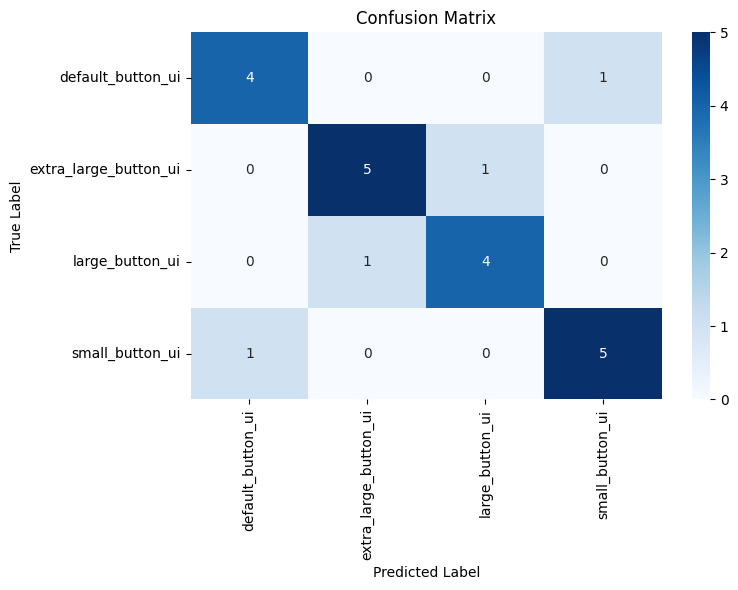

In [8]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Best model prediction
y_pred = pipeline.best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")

plt.tight_layout()
plt.show()

Classification Report (Mandatory)

In [9]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_
    )
)

                       precision    recall  f1-score   support

    default_button_ui       0.80      0.80      0.80         5
extra_large_button_ui       0.83      0.83      0.83         6
      large_button_ui       0.80      0.80      0.80         5
      small_button_ui       0.83      0.83      0.83         6

             accuracy                           0.82        22
            macro avg       0.82      0.82      0.82        22
         weighted avg       0.82      0.82      0.82        22



In [10]:
report = classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_,
    output_dict=True
)

import pandas as pd

pd.DataFrame(report).transpose().to_csv(
    "classification_report.csv"
)

print("Classification Report Saved.")

Classification Report Saved.


                Feature  Importance
6          tap_accuracy    0.517406
3            total_taps    0.155504
5             miss_taps    0.097958
1          screen_width    0.066903
7  avg_reaction_time_ms    0.063790
2         screen_height    0.040060
0                   age    0.036352
4       successful_taps    0.022029
8             miss_rate    0.000000
9         reaction_norm    0.000000


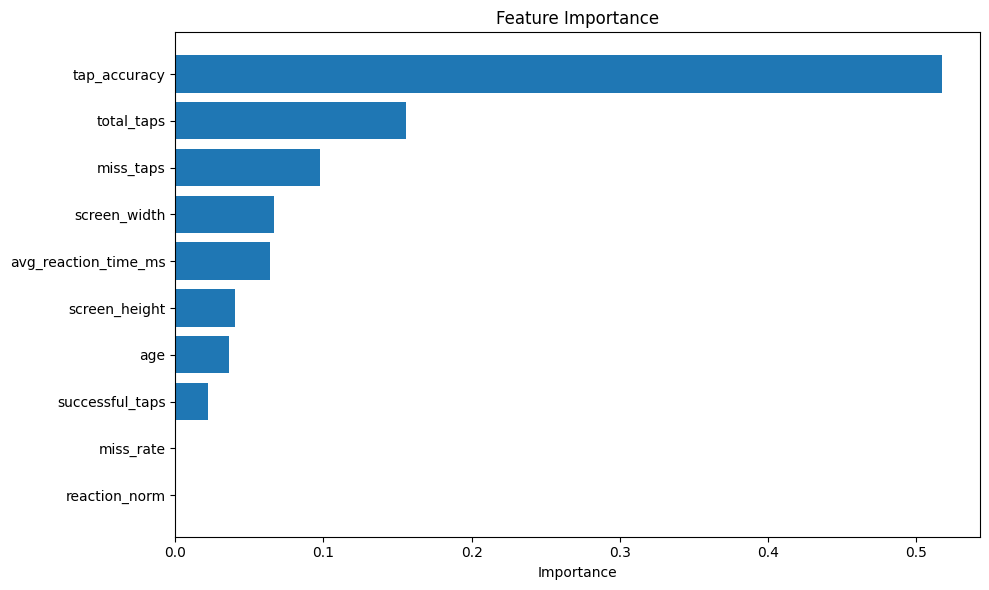

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pipeline.best_model.feature_importances_

feature_importance = pd.DataFrame({

    "Feature": features,

    "Importance": importance

})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

plt.figure(figsize=(10,6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Feature Importance")

plt.xlabel("Importance")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

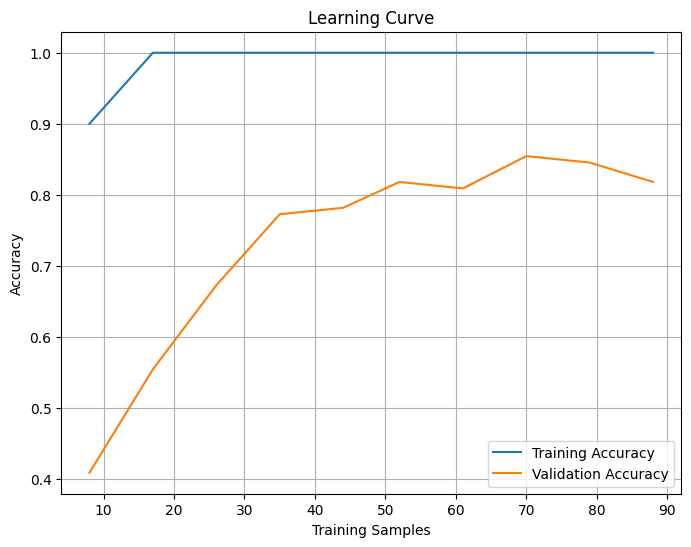

In [12]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, test_scores = learning_curve(

    pipeline.best_model,

    X,

    y,

    cv=5,

    train_sizes=np.linspace(0.1,1.0,10),

    scoring="accuracy"

)

train_mean = train_scores.mean(axis=1)

test_mean = test_scores.mean(axis=1)

plt.figure(figsize=(8,6))

plt.plot(train_sizes,train_mean,label="Training Accuracy")

plt.plot(train_sizes,test_mean,label="Validation Accuracy")

plt.xlabel("Training Samples")

plt.ylabel("Accuracy")

plt.title("Learning Curve")

plt.legend()

plt.grid()

plt.show()